# Model 2 · 7. Tuning parameter

**Tuning** = mencoba beberapa pengaturan (parameter) model, menilai tiap pengaturan dengan **val**, lalu memilih yang terbaik.
Analogi: mencoba beberapa takaran air di rice cooker, mencicipi, lalu memilih yang paling enak.

Aturan supaya jujur:
1. Semua pilihan dibuat dengan **val** (macro F1). Soal **ujian** hanya dipakai **sekali** di bagian terakhir.
2. Tidak memakai cross-validation acak di train, karena di train masih ada kembaran (foto dibalik/diputar) sehingga nilainya naik palsu.
3. Selisih di bawah sekitar 0,005 dianggap naik-turun biasa.

Langkah:
1. Tuning tiap model sendiri-sendiri (RF, ET, HGB) dengan 60 ciri.
2. Gabungkan parameter terbaik, coba bobot suara dan ciri ukuran (dari percobaan ciri ukuran relatif), 3 seed.
3. Ujian sekali: model sekarang vs pilihan tuning.

Model final di `models/` **tidak diubah**. Hasil tabel disimpan ke `hasil/model2/tuning/`. *Bukan alat diagnosis medis.*
Butuh notebook `2_preprocessing_ciri` sudah dijalankan. Waktu sekitar 45–60 menit.

## 1. Persiapan data

In [1]:
from pathlib import Path
import sys, time, itertools

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

KELAS = ['Blackheads', 'Cyst', 'Papules', 'Pustules', 'Whiteheads']
D = ROOT / 'data' / 'jenis_v3'
SIMPAN = ROOT / 'hasil' / 'model2' / 'tuning'
SIMPAN.mkdir(parents=True, exist_ok=True)

z = np.load(ROOT / 'hasil' / 'model2' / 'ciri_warna_titik.npz')
X60 = {k: z[k] for k in ('latih', 'val', 'ujian')}
y = {k: z['y_' + k] for k in X60}
print({k: v.shape for k, v in X60.items()})

{'latih': (8618, 60), 'val': (802, 60), 'ujian': (795, 60)}


### Ciri ukuran (5 ciri tambahan)
Setiap potongan dikecilkan/dibesarkan ke 64x64, jadi model tidak tahu ukuran asli jerawat. Dari `manifest_potongan_v2.csv`
(foto asal dan ukuran tiap potongan) dihitung: ukuran piksel asli (log), ukuran dibanding median dan dibanding yang terbesar
di foto yang sama, peringkat ukuran di foto itu, dan jumlah jerawat di foto. Foto close-up di train tidak punya info ini (kosong/NaN).
Urutan file sama dengan notebook 2.

In [2]:
def daftar(bagian, hanya_potongan=False):
    return [f for k in KELAS for f in sorted((D / bagian / k).glob('*')) if not hanya_potongan or f.name.startswith('C_')]


P = {'latih': daftar('train'), 'val': daftar('val', True), 'ujian': daftar('test_potongan')}
m = pd.read_csv(D / 'manifest_potongan_v2.csv')
g = m.groupby('gambar_asli').sisi_px
m['n_foto'] = g.transform('size')
m['rel'] = m.sisi_px / g.transform('median')
m['rank'] = g.rank(pct=True)
m['rel_maks'] = m.sisi_px / g.transform('max')
info = m.set_index('file_baru')
NAMA_UKURAN = ['log_sisi', 'rel_median', 'rank_foto', 'rel_maks', 'log_n_kotak']


def ciri_ukuran(paths):
    out = np.full((len(paths), 5), np.nan)
    for i, p in enumerate(paths):
        if p.name in info.index:
            r = info.loc[p.name]
            out[i] = [np.log(r.sisi_px), r.rel, r['rank'], r.rel_maks, np.log(r.n_foto)]
    return out


X65 = {k: np.hstack([X60[k], ciri_ukuran(P[k])]) for k in P}
for k in P:
    assert len(P[k]) == len(X60[k])
print('tanpa info ukuran:', {k: int(np.isnan(X65[k][:, -1]).sum()) for k in P})
pd.DataFrame(X65['latih'][:, -5:], columns=NAMA_UKURAN).assign(jenis=[KELAS[i] for i in y['latih']]).groupby('jenis').median().round(2)

tanpa info ukuran: {'latih': 2105, 'val': 0, 'ujian': 0}


,log_sisi,rel_median,rank_foto,rel_maks,log_n_kotak
jenis,,,,,
Blackheads,3.71,1.00,0.50,0.58,2.40
Cyst,4.05,1.18,0.80,0.76,2.20
Papules,3.81,1.00,0.60,0.62,2.40
Pustules,3.74,1.00,0.53,0.60,2.48
Whiteheads,3.71,0.98,0.50,0.55,2.64


In [3]:
def nilai(model, X, bagian='val'):
    p = model.predict(X[bagian])
    f1 = f1_score(y[bagian], p, average=None)
    return {'akurasi': accuracy_score(y[bagian], p), 'macro_F1': f1.mean(), 'Cyst_F1': f1[1], 'Papules_F1': f1[2]}


def coba(nama, buat, kisi, X=X60, seed=0):
    """Latih satu model untuk tiap kombinasi di kisi, nilai dengan val."""
    baris = []
    kunci = list(kisi)
    for nilai_ in itertools.product(*kisi.values()):
        par = dict(zip(kunci, nilai_))
        t0 = time.time()
        mod = buat(seed=seed, **par).fit(X['latih'], y['latih'])
        baris.append({**par, **nilai(mod, X), 'detik': round(time.time() - t0)})
        print(nama, par, f"val F1 {baris[-1]['macro_F1']:.3f}", flush=True)
    tabel = pd.DataFrame(baris).sort_values('macro_F1', ascending=False).reset_index(drop=True)
    tabel.to_csv(SIMPAN / f'tuning_{nama}.csv', index=False)
    return tabel

## 2. Tuning Random Forest
| Parameter | Dicoba | Arti |
|---|---|---|
| `max_features` | log2 (≈6), sqrt (≈8), 0.3 (18) | berapa ciri yang dilihat di tiap cabang |
| `min_samples_leaf` | 1, 2, 4 | isi minimal satu daun (lebih besar = lebih tahan label salah) |

Jumlah pohon tetap 300 (menambah pohon hanya membuat lebih stabil, tidak lebih pintar). Sekarang: **log2, 1**.

In [4]:
def buat_rf(seed, max_features, min_samples_leaf):
    return RandomForestClassifier(300, max_features=max_features, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=seed)


rf_tabel = coba('RF', buat_rf, {'max_features': ['log2', 'sqrt', 0.3], 'min_samples_leaf': [1, 2, 4]})
rf_tabel.round(3)

RF {'max_features': 'log2', 'min_samples_leaf': 1} val F1 0.680
RF {'max_features': 'log2', 'min_samples_leaf': 2} val F1 0.672
RF {'max_features': 'log2', 'min_samples_leaf': 4} val F1 0.645
RF {'max_features': 'sqrt', 'min_samples_leaf': 1} val F1 0.681
RF {'max_features': 'sqrt', 'min_samples_leaf': 2} val F1 0.670
RF {'max_features': 'sqrt', 'min_samples_leaf': 4} val F1 0.655
RF {'max_features': 0.3, 'min_samples_leaf': 1} val F1 0.688
RF {'max_features': 0.3, 'min_samples_leaf': 2} val F1 0.668
RF {'max_features': 0.3, 'min_samples_leaf': 4} val F1 0.651


,max_features,min_samples_leaf,akurasi,macro_F1,Cyst_F1,Papules_F1,detik
0,0.3,1,0.713,0.688,0.500,0.678,5
1,sqrt,1,0.711,0.681,0.483,0.696,2
2,log2,1,0.708,0.680,0.482,0.680,1
3,log2,2,0.701,0.672,0.475,0.681,1
4,sqrt,2,0.700,0.670,0.475,0.686,2
5,0.3,2,0.696,0.668,0.475,0.665,4
6,sqrt,4,0.682,0.655,0.478,0.660,2
7,0.3,4,0.686,0.651,0.417,0.665,4
8,log2,4,0.676,0.645,0.439,0.655,1


## 3. Tuning Extra Trees
| Parameter | Dicoba |
|---|---|
| `max_features` | sqrt (≈8), 0.3 (18), 0.5 (30) |
| `min_samples_leaf` | 1, 2, 3 |

Jumlah pohon tetap 500. Sekarang: **sqrt, 1**.

In [5]:
def buat_et(seed, max_features, min_samples_leaf):
    return ExtraTreesClassifier(500, max_features=max_features, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=seed)


et_tabel = coba('ET', buat_et, {'max_features': ['sqrt', 0.3, 0.5], 'min_samples_leaf': [1, 2, 3]})
et_tabel.round(3)

ET {'max_features': 'sqrt', 'min_samples_leaf': 1} val F1 0.699
ET {'max_features': 'sqrt', 'min_samples_leaf': 2} val F1 0.684
ET {'max_features': 'sqrt', 'min_samples_leaf': 3} val F1 0.686
ET {'max_features': 0.3, 'min_samples_leaf': 1} val F1 0.698
ET {'max_features': 0.3, 'min_samples_leaf': 2} val F1 0.687
ET {'max_features': 0.3, 'min_samples_leaf': 3} val F1 0.687
ET {'max_features': 0.5, 'min_samples_leaf': 1} val F1 0.707
ET {'max_features': 0.5, 'min_samples_leaf': 2} val F1 0.689
ET {'max_features': 0.5, 'min_samples_leaf': 3} val F1 0.688


,max_features,min_samples_leaf,akurasi,macro_F1,Cyst_F1,Papules_F1,detik
0,0.5,1,0.733,0.707,0.513,0.685,3
1,sqrt,1,0.733,0.699,0.466,0.713,3
2,0.3,1,0.726,0.698,0.505,0.692,3
3,0.5,2,0.716,0.689,0.491,0.669,2
4,0.5,3,0.718,0.688,0.470,0.679,2
5,0.3,3,0.718,0.687,0.474,0.686,2
6,0.3,2,0.717,0.687,0.478,0.679,2
7,sqrt,3,0.717,0.686,0.474,0.685,3
8,sqrt,2,0.717,0.684,0.464,0.690,3


## 4. Tuning HistGradientBoosting
| Parameter | Dicoba | Arti |
|---|---|---|
| `laju` | 0,03 x 800 pohon, 0,05 x 500, 0,1 x 250 | belajar pelan-lama atau cepat-singkat (jumlah langkah kira-kira sama) |
| `l2_regularization` | 0, 1 | "rem" supaya tidak menghafal |
| `min_samples_leaf` | 20, 60 | isi minimal satu daun |
| `max_leaf_nodes` | 15, 31 | ukuran tiap pohon |

Sekarang: **0,05 x 500, l2 0, daun 20, 31 simpul**.

In [6]:
LAJU = {'0.03x800': (0.03, 800), '0.05x500': (0.05, 500), '0.1x250': (0.1, 250)}


def buat_hgb(seed, laju, l2_regularization, min_samples_leaf, max_leaf_nodes):
    lr, it = LAJU[laju]
    return HistGradientBoostingClassifier(learning_rate=lr, max_iter=it, l2_regularization=l2_regularization,
                                          min_samples_leaf=min_samples_leaf, max_leaf_nodes=max_leaf_nodes, random_state=seed)


hgb_tabel = coba('HGB', buat_hgb, {'laju': list(LAJU), 'l2_regularization': [0.0, 1.0],
                                   'min_samples_leaf': [20, 60], 'max_leaf_nodes': [15, 31]})
hgb_tabel.round(3)

HGB {'laju': '0.03x800', 'l2_regularization': 0.0, 'min_samples_leaf': 20, 'max_leaf_nodes': 15} val F1 0.712
HGB {'laju': '0.03x800', 'l2_regularization': 0.0, 'min_samples_leaf': 20, 'max_leaf_nodes': 31} val F1 0.728
HGB {'laju': '0.03x800', 'l2_regularization': 0.0, 'min_samples_leaf': 60, 'max_leaf_nodes': 15} val F1 0.707
HGB {'laju': '0.03x800', 'l2_regularization': 0.0, 'min_samples_leaf': 60, 'max_leaf_nodes': 31} val F1 0.707
HGB {'laju': '0.03x800', 'l2_regularization': 1.0, 'min_samples_leaf': 20, 'max_leaf_nodes': 15} val F1 0.691
HGB {'laju': '0.03x800', 'l2_regularization': 1.0, 'min_samples_leaf': 20, 'max_leaf_nodes': 31} val F1 0.722
HGB {'laju': '0.03x800', 'l2_regularization': 1.0, 'min_samples_leaf': 60, 'max_leaf_nodes': 15} val F1 0.694
HGB {'laju': '0.03x800', 'l2_regularization': 1.0, 'min_samples_leaf': 60, 'max_leaf_nodes': 31} val F1 0.715
HGB {'laju': '0.05x500', 'l2_regularization': 0.0, 'min_samples_leaf': 20, 'max_leaf_nodes': 15} val F1 0.713
HGB {'laju

,laju,l2_regularization,min_samples_leaf,max_leaf_nodes,akurasi,macro_F1,Cyst_F1,Papules_F1,detik
0,0.03x800,0.0,20,31,0.749,0.728,0.562,0.723,49
1,0.05x500,0.0,20,31,0.744,0.726,0.587,0.721,24
2,0.05x500,1.0,20,31,0.744,0.725,0.574,0.716,26
3,0.03x800,1.0,20,31,0.746,0.722,0.534,0.712,19
4,0.1x250,1.0,20,31,0.742,0.720,0.565,0.725,13
5,0.05x500,0.0,60,31,0.738,0.719,0.569,0.707,22
6,0.03x800,1.0,60,31,0.739,0.715,0.538,0.711,22
7,0.1x250,0.0,20,31,0.734,0.713,0.551,0.704,14
8,0.05x500,0.0,20,15,0.733,0.713,0.553,0.698,7
9,0.03x800,0.0,20,15,0.729,0.712,0.567,0.690,10


### Seberapa jauh beda pengaturan terbaik dan terburuk?
Kalau rentangnya kecil, artinya parameter memang tidak banyak berpengaruh (batasnya ada di data dan ciri).

,terburuk,pengaturan sekarang,terbaik
RF,0.645,0.680,0.688
ET,0.684,0.699,0.707
HGB,0.689,0.726,0.728


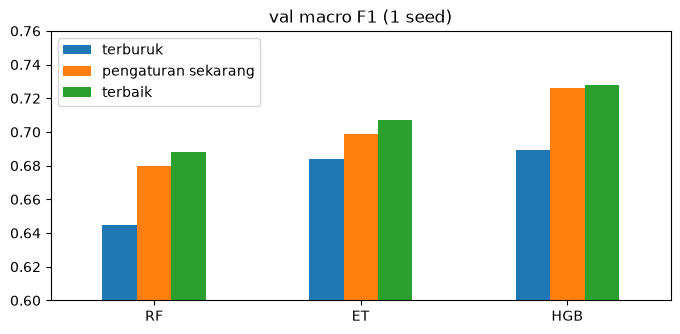

In [7]:
ringkas = pd.DataFrame({n: {'terburuk': t.macro_F1.min(), 'pengaturan sekarang': t.macro_F1[i].item(), 'terbaik': t.macro_F1.max()}
                        for n, t, i in [('RF', rf_tabel, (rf_tabel.max_features == 'log2') & (rf_tabel.min_samples_leaf == 1)),
                                        ('ET', et_tabel, (et_tabel.max_features == 'sqrt') & (et_tabel.min_samples_leaf == 1)),
                                        ('HGB', hgb_tabel, (hgb_tabel.laju == '0.05x500') & (hgb_tabel.l2_regularization == 0)
                                         & (hgb_tabel.min_samples_leaf == 20) & (hgb_tabel.max_leaf_nodes == 31))]}).T.round(3)
display(ringkas)
ringkas.plot.bar(rot=0, ylim=(0.6, 0.76), figsize=(8, 3.5), title='val macro F1 (1 seed)'); plt.show()

## 5. Gabungan: parameter terbaik, bobot suara, dan ciri ukuran
Kandidat dinilai dengan **3 seed** (rata-rata), supaya tidak memilih yang menang karena kebetulan.
- **sekarang**: parameter lama, 60 ciri (model final saat ini)
- **tuning**: parameter terbaik tiap model, bobot 1:1:1 atau 1:1:2 (suara HGB dua kali)
- masing-masing dengan 60 ciri atau 65 ciri (+ ukuran)

In [8]:
def terbaik(t, kolom):
    return {k: (v.item() if hasattr(v, 'item') else v) for k, v in t.iloc[0][kolom].items()}


par_rf = terbaik(rf_tabel, ['max_features', 'min_samples_leaf'])
par_et = terbaik(et_tabel, ['max_features', 'min_samples_leaf'])
par_hgb = terbaik(hgb_tabel, ['laju', 'l2_regularization', 'min_samples_leaf', 'max_leaf_nodes'])
for k, v in par_rf.items():
    if isinstance(v, float) and v.is_integer() and k == 'min_samples_leaf':
        par_rf[k] = int(v)
print('RF :', par_rf); print('ET :', par_et); print('HGB:', par_hgb)
LAMA = ({'max_features': 'log2', 'min_samples_leaf': 1}, {'max_features': 'sqrt', 'min_samples_leaf': 1},
        {'laju': '0.05x500', 'l2_regularization': 0.0, 'min_samples_leaf': 20, 'max_leaf_nodes': 31})


def gabungan(seed, pr, pe, ph, bobot):
    pr = {k: int(v) if k == 'min_samples_leaf' else v for k, v in pr.items()}
    pe = {k: int(v) if k == 'min_samples_leaf' else v for k, v in pe.items()}
    ph = {k: int(v) if k in ('min_samples_leaf', 'max_leaf_nodes') else v for k, v in ph.items()}
    return VotingClassifier([('rf', buat_rf(seed, **pr)), ('et', buat_et(seed, **pe)), ('hgb', buat_hgb(seed, **ph))],
                            voting='soft', weights=bobot)


KANDIDAT = {
    'sekarang (60 ciri)': (LAMA, None, X60),
    'sekarang + ukuran (65)': (LAMA, None, X65),
    'tuning 1:1:1 (60 ciri)': ((par_rf, par_et, par_hgb), None, X60),
    'tuning 1:1:2 (60 ciri)': ((par_rf, par_et, par_hgb), [1, 1, 2], X60),
    'tuning 1:1:1 + ukuran (65)': ((par_rf, par_et, par_hgb), None, X65),
    'tuning 1:1:2 + ukuran (65)': ((par_rf, par_et, par_hgb), [1, 1, 2], X65),
}
baris = []
for nama, (par, bobot, X) in KANDIDAT.items():
    for s in (0, 1, 2):
        mod = gabungan(s, *par, bobot).fit(X['latih'], y['latih'])
        baris.append({'kandidat': nama, 'seed': s, **nilai(mod, X)})
    print(nama, 'selesai', flush=True)
gab_tabel = pd.DataFrame(baris)
gab_tabel.to_csv(SIMPAN / 'tuning_gabungan_val.csv', index=False)
gab_ringkas = gab_tabel.groupby('kandidat', sort=False)[['akurasi', 'macro_F1', 'Cyst_F1', 'Papules_F1']].agg(['mean', 'std']).round(3)
gab_ringkas

RF : {'max_features': 0.3, 'min_samples_leaf': 1}
ET : {'max_features': 0.5, 'min_samples_leaf': 1}
HGB: {'laju': '0.03x800', 'l2_regularization': 0.0, 'min_samples_leaf': 20, 'max_leaf_nodes': 31}
sekarang (60 ciri) selesai
sekarang + ukuran (65) selesai
tuning 1:1:1 (60 ciri) selesai
tuning 1:1:2 (60 ciri) selesai
tuning 1:1:1 + ukuran (65) selesai
tuning 1:1:2 + ukuran (65) selesai


akurasi        macro_F1        Cyst_F1         \
                              mean    std     mean    std    mean    std   
kandidat                                                                   
sekarang (60 ciri)           0.748  0.002    0.729  0.002   0.577  0.003   
sekarang + ukuran (65)       0.743  0.003    0.728  0.003   0.600  0.007   
tuning 1:1:1 (60 ciri)       0.737  0.001    0.711  0.002   0.518  0.010   
tuning 1:1:2 (60 ciri)       0.744  0.004    0.718  0.003   0.532  0.000   
tuning 1:1:1 + ukuran (65)   0.747  0.001    0.732  0.002   0.611  0.009   
tuning 1:1:2 + ukuran (65)   0.746  0.003    0.729  0.004   0.595  0.014   

                           Papules_F1         
                                 mean    std  
kandidat                                      
sekarang (60 ciri)              0.712  0.004  
sekarang + ukuran (65)          0.703  0.004  
tuning 1:1:1 (60 ciri)          0.706  0.003  
tuning 1:1:2 (60 ciri)          0.715  0.008  
tuning 1:1:1 + ukuran (65)      0.713  0.003  
tuning 1:1:2 + ukuran (65)      0.716  0.006

terbaik di val: tuning 1:1:1 + ukuran (65)  (macro F1 0.732, selisih dengan sekarang +0.004)
Selisih < 0,005: masih naik-turun biasa. Tuning TIDAK memberi kenaikan yang jelas.


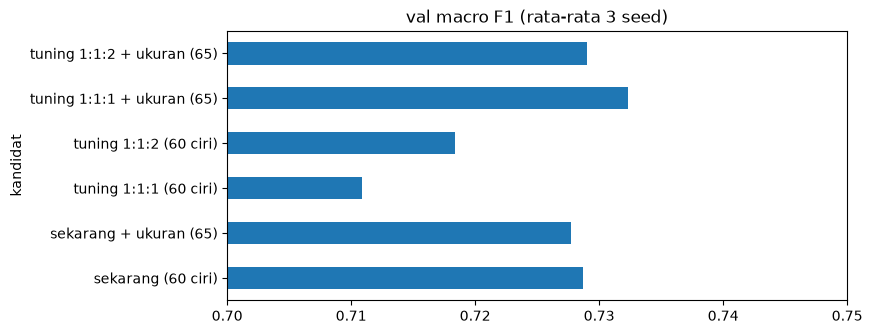

In [9]:
rata = gab_tabel.groupby('kandidat', sort=False).macro_F1.mean()
PILIH = rata.idxmax()
selisih = rata[PILIH] - rata['sekarang (60 ciri)']
print(f'terbaik di val: {PILIH}  (macro F1 {rata[PILIH]:.3f}, selisih dengan sekarang {selisih:+.3f})')
if selisih < 0.005:
    print('Selisih < 0,005: masih naik-turun biasa. Tuning TIDAK memberi kenaikan yang jelas.')
rata.plot.barh(xlim=(0.70, 0.75), figsize=(8, 3.5), title='val macro F1 (rata-rata 3 seed)'); plt.show()

## 6. Ujian (sekali saja)
Hanya 2 model yang diuji: **sekarang** dan **pilihan val**. Ujian tidak dipakai untuk memilih.

In [10]:
hasil_ujian, cm = [], {}
for nama in dict.fromkeys(['sekarang (60 ciri)', PILIH]):
    par, bobot, X = KANDIDAT[nama]
    for s in (0, 1, 2):
        mod = gabungan(s, *par, bobot).fit(X['latih'], y['latih'])
        hasil_ujian.append({'kandidat': nama, 'seed': s, **nilai(mod, X, 'ujian')})
        cm.setdefault(nama, []).append(confusion_matrix(y['ujian'], mod.predict(X['ujian']), labels=range(5)))
ujian_tabel = pd.DataFrame(hasil_ujian)
ujian_tabel.to_csv(SIMPAN / 'tuning_ujian.csv', index=False)
ujian_tabel.groupby('kandidat', sort=False)[['akurasi', 'macro_F1', 'Cyst_F1', 'Papules_F1']].mean().round(3)

,akurasi,macro_F1,Cyst_F1,Papules_F1
kandidat,,,,
sekarang (60 ciri),0.733,0.713,0.599,0.748
tuning 1:1:1 + ukuran (65),0.728,0.716,0.640,0.723


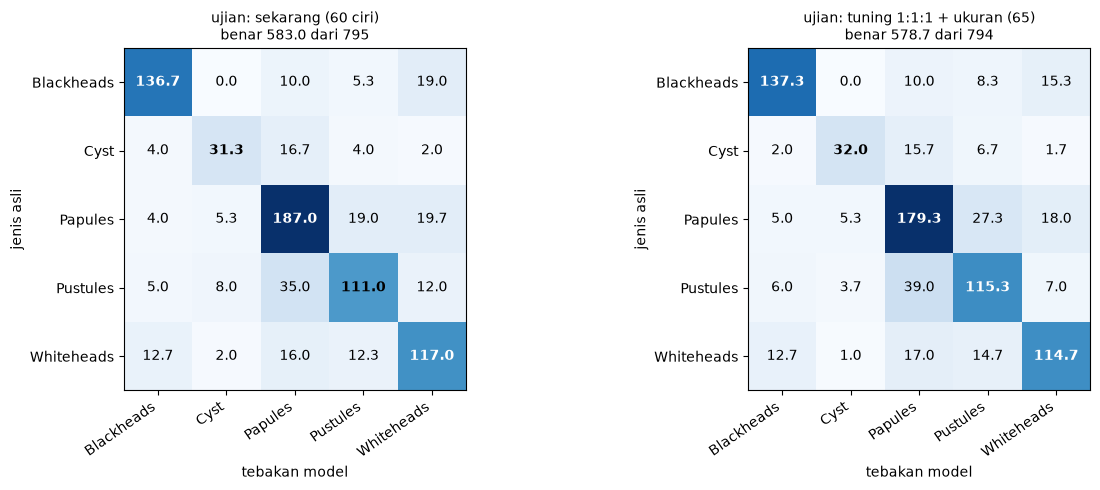

In [11]:
fig, ax = plt.subplots(1, len(cm), figsize=(6.5 * len(cm), 5), squeeze=False)
for a, (nama, daftar_cm) in zip(ax[0], cm.items()):
    c = np.mean(daftar_cm, 0)
    a.imshow(c, cmap='Blues')
    for i in range(5):
        for j in range(5):
            a.text(j, i, f'{c[i, j]:.1f}', ha='center', va='center', color='white' if c[i, j] > c.max() * 0.6 else 'black',
                   fontweight='bold' if i == j else 'normal')
    a.set_xticks(range(5), KELAS, rotation=35, ha='right'); a.set_yticks(range(5), KELAS)
    a.set_xlabel('tebakan model'); a.set_ylabel('jenis asli'); a.set_title(f'ujian: {nama}\nbenar {np.trace(c):.1f} dari {int(c.sum())}', fontsize=10)
plt.tight_layout(); plt.show()

## 7. Kesimpulan
Baca hasil di atas:
- Kalau selisih val < 0,005, tuning **tidak** memberi kenaikan jelas → model final tetap. Ini tetap hasil yang berguna:
  membuktikan bahwa batas nilai ada di **data dan ciri**, bukan di parameter.
- Kalau val naik jelas **dan** ujian tidak turun, model pilihan tuning bisa dipertimbangkan sebagai model final baru
  (perlu dilatih ulang dan disimpan dengan nama baru; model lama tidak ditimpa).
- Ciri ukuran: kalau dipakai, aplikasi harus menghitung ukuran relatif dari kotak model 1 (bukan kotak label manusia),
  sehingga perlu dicek lagi di foto sungguhan.